Using device: cuda

--- شروع فرآیند آموزش مدل ---
Epoch [1/15] | زمان: 6.5s | خطا (Loss): 0.7034 | دقت: 46.0%
Epoch [2/15] | زمان: 6.1s | خطا (Loss): 0.6641 | دقت: 63.0%
Epoch [3/15] | زمان: 6.2s | خطا (Loss): 0.6397 | دقت: 68.0%
Epoch [4/15] | زمان: 6.4s | خطا (Loss): 0.6062 | دقت: 71.0%
Epoch [5/15] | زمان: 6.2s | خطا (Loss): 0.5457 | دقت: 77.0%
Epoch [6/15] | زمان: 6.1s | خطا (Loss): 0.5485 | دقت: 74.0%
Epoch [7/15] | زمان: 6.1s | خطا (Loss): 0.5081 | دقت: 77.0%
Epoch [8/15] | زمان: 6.1s | خطا (Loss): 0.4876 | دقت: 77.0%
Epoch [9/15] | زمان: 6.1s | خطا (Loss): 0.4265 | دقت: 80.0%
Epoch [10/15] | زمان: 6.2s | خطا (Loss): 0.3956 | دقت: 85.0%
Epoch [11/15] | زمان: 6.2s | خطا (Loss): 0.3536 | دقت: 88.0%
Epoch [12/15] | زمان: 6.3s | خطا (Loss): 0.3556 | دقت: 83.0%
Epoch [13/15] | زمان: 6.3s | خطا (Loss): 0.2765 | دقت: 90.0%
Epoch [14/15] | زمان: 6.3s | خطا (Loss): 0.2467 | دقت: 90.0%
Epoch [15/15] | زمان: 6.2s | خطا (Loss): 0.1692 | دقت: 95.0%

--- شروع ارزیابی روی داده‌های تست ---
احتما

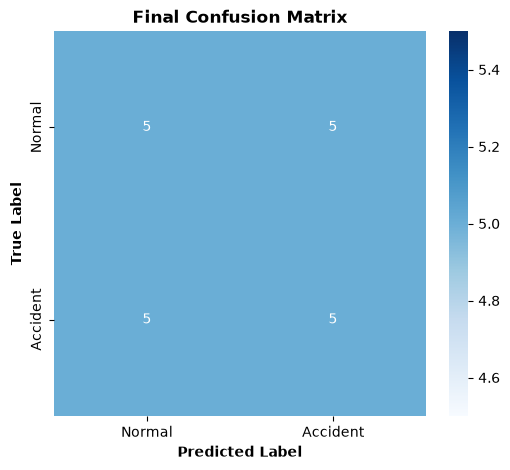

مدل نهایی با موفقیت ذخیره شد.


In [14]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ==========================================
# 1. کلاس مدیریت داده‌ها (Dataset)
# ==========================================
class AccidentDataset(Dataset):
    def __init__(self, data_dir, max_frames=40):
        self.data_dir = data_dir
        self.file_names = [f for f in os.listdir(data_dir) if f.endswith('.pt')]
        self.max_frames = max_frames
        self.normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.data_dir, self.file_names[idx])
        frames = torch.load(file_path, weights_only=True)
        
        if frames.dtype == torch.uint8:
            frames = frames.float() / 255.0
            
        frames = torch.stack([self.normalize(f) for f in frames])
        seq_len = frames.size(0)
        
        if seq_len >= self.max_frames:
            frames = frames[:self.max_frames]
        else:
            padding = torch.zeros((self.max_frames - seq_len, 3, 224, 224))
            frames = torch.cat((frames, padding), dim=0)
            
        # تبدیل امن نام فایل به لیبل (حل مشکل 1.0)
        label = int(float(self.file_names[idx].split('_label_')[1].split('.pt')[0]))
        return frames, torch.tensor([label], dtype=torch.float32)

# ==========================================
# 2. معماری شبکه ترکیبی CNN-LSTM (اصلاح شده)
# ==========================================
class CNN_LSTM_Model(nn.Module):
    def __init__(self, hidden_size=256, num_layers=1):
        super(CNN_LSTM_Model, self).__init__()
        
        resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.cnn = nn.Sequential(*list(resnet.children())[:-1])
        
        for param in self.cnn.parameters():
            param.requires_grad = False
            
        self.lstm = nn.LSTM(input_size=512, hidden_size=hidden_size, 
                            num_layers=num_layers, batch_first=True)
        
        # لایه Dropout برای جلوگیری از حفظ کردن داده‌ها
        self.dropout = nn.Dropout(0.3) 
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        batch_size, timesteps, C, H, W = x.size()
        x = x.view(batch_size * timesteps, C, H, W)
        
        # جلوگیری از تغییر ناخواسته وزن‌های ResNet
        self.cnn.eval() 
        with torch.no_grad():
            features = self.cnn(x) 
            
        features = features.view(features.size(0), -1) 
        features = features.view(batch_size, timesteps, -1) 
        
        lstm_out, _ = self.lstm(features)
        
        # تغییر کلیدی: گرفتن میانگین از کل فریم‌ها برای خنثی کردن پدینگ‌های سیاه
        pooled_out = torch.mean(lstm_out, dim=1) 
        
        pooled_out = self.dropout(pooled_out)
        out = self.fc(pooled_out)
        return self.sigmoid(out)

# ==========================================
# 3. تست، آموزش و ارزیابی
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # بارگذاری داده‌ها
    train_dataset = AccidentDataset('./train_sample_100')
    test_dataset = AccidentDataset('./test_sample_20')
    train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False)

    # راه‌اندازی مدل و تنظیمات آموزش
    model = CNN_LSTM_Model().to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0001)
    num_epochs = 15

    # --- حلقه آموزش ---
    print("\n--- شروع فرآیند آموزش مدل ---")
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_train, total_train = 0, 0
        
        start_time = time.time()
        for videos, labels in train_loader:
            videos, labels = videos.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(videos)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            predicted = (outputs > 0.5).float()
            correct_train += (predicted == labels).sum().item()
            total_train += labels.size(0)
            
        epoch_time = time.time() - start_time
        print(f"Epoch [{epoch+1}/{num_epochs}] | "
              f"زمان: {epoch_time:.1f}s | "
              f"خطا (Loss): {running_loss/len(train_loader):.4f} | "
              f"دقت: {100*correct_train/total_train:.1f}%")

    # --- فاز ارزیابی ---
    print("\n--- شروع ارزیابی روی داده‌های تست ---")
    model.eval()
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for videos, labels in test_loader:
            outputs = model(videos.to(device))
            print(f"احتمالات خام: {outputs.squeeze().tolist()}") # برای دیباگ
            predicted = (outputs > 0.5).float().cpu().numpy()
            all_preds.extend(predicted)
            all_labels.extend(labels.numpy())

    all_preds = np.array(all_preds).flatten()
    all_labels = np.array(all_labels).flatten()

    print("\n--- گزارش نهایی ---")
    print(classification_report(all_labels, all_preds, target_names=['Normal (0)', 'Accident (1)']))

    # رسم ماتریس درهم‌ریختگی
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Normal', 'Accident'], 
                yticklabels=['Normal', 'Accident'])
    plt.xlabel('Predicted Label', fontweight='bold')
    plt.ylabel('True Label', fontweight='bold')
    plt.title('Final Confusion Matrix', fontweight='bold')
    plt.show()
    
    # ذخیره مدل
    torch.save(model.state_dict(), 'accident_cnn_lstm_model_final.pth')
    print("مدل نهایی با موفقیت ذخیره شد.")

## Try 1

مدل اولیه روی ۱۰۰ نمونه

### چه کاری کردیم

یک مدل ساده ساختیم که از هر ویدئو ۴۰ فریم می‌گیرد و پیش‌بینی می‌کند تصادف است یا نه.

معماری دو بخش دارد.

بخش اول:

ResNet18

برای استخراج ویژگی از هر فریم. وزن‌های این بخش را فریز کردیم، یعنی آموزش نمی‌بینند. چون ۱۰۰ نمونه برای

fine-tune

کردن یک شبکه بزرگ خیلی کم است.

بخش دوم:

LSTM

برای مدل‌سازی ترتیب فریم‌ها. این بخش آموزش می‌بیند.

### تنظیمات

تابع خطا:

`BCELoss`

بهینه‌ساز:

`Adam`

نرخ یادگیری:

`1e-4`

تعداد ایپاک:

۱۵

### نتیجه

دقت آموزش به ۹۵ درصد رسید.

دقت تست روی ۵۰ درصد ماند.

یعنی مدل روی داده آموزش خوب یاد گرفت ولی روی داده جدید شکست خورد.

این پدیده اسمش

overfitting

است.

### چرا این اتفاق افتاد

داده خیلی کم بود. فقط ۱۰۰ نمونه.

مدل به‌جای یادگیری الگوی تصادف، نمونه‌ها را حفظ کرد.

### نتیجه‌گیری

این آزمایش یک شکست بود، ولی مهم بود. فهمیدیم ۱۰۰ نمونه کافی نیست. در آزمایش‌های بعدی داده را بیشتر کردیم، معماری را عوض کردیم و از

Focal Loss

استفاده کردیم.